In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("/Users/assalim/Desktop/Master/Custom CNN Audio DeepFake Detection/results/train_all/results.csv")
df["eer"] = df["eer"]  * 100
df.head()

,seed,pooling,wavelet,node,eval_split,eer,roc_auc,best_epoch,best_dev_eer,train_time_s
0,42,wavelet,db4,aaa,ASVspoof 2019,8.905494,0.968398,7,0.070244,1560.8
1,42,wavelet,db4,aad,ASVspoof 2019,5.995675,0.983775,10,0.047891,1957.2
2,42,wavelet,db4,add,ASVspoof 2019,7.519405,0.976639,26,0.048665,3739.5
3,42,wavelet,db4,ada,ASVspoof 2019,7.475530,0.976887,10,0.059323,1899.2
4,42,wavelet,db4,dda,ASVspoof 2019,10.034058,0.962619,18,0.086340,2872.3


In [3]:
df = df[df["seed"] == 42]

In [4]:
asv_2019 = df[df["eval_split"] == "ASVspoof 2019"]
asv_2021 = df[df["eval_split"] == "ASVspoof 2021"]

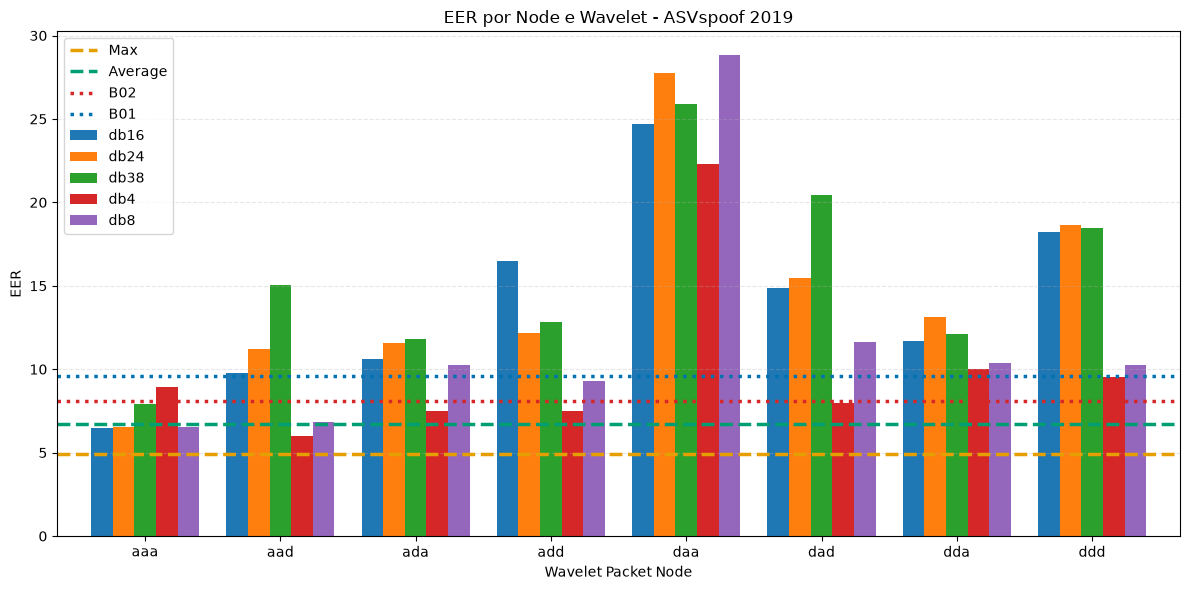

In [ ]:
pivot = asv_2019.pivot_table(
    index="node",
    columns="wavelet",
    values="eer",
    aggfunc="mean"
)

eer_max = asv_2019.loc[
    asv_2019["pooling"] == "max", "eer"
].mean()

eer_avg = asv_2019.loc[
    asv_2019["pooling"] == "average", "eer"
].mean()

# Plot
ax = pivot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

# Pooling baselines
ax.axhline(
    y=eer_max,
    color="#E69F00",       # Laranja queimado
    linestyle="--",
    linewidth=2.5,
    label="Max"
)

ax.axhline(
    y=eer_avg,
    color="#009E73",       # Verde
    linestyle="--",
    linewidth=2.5,
    label="Average"
)

# GMM baselines
ax.axhline(
    y=8.09,
    color="#D62728",       # Vermelho escuro
    linestyle=":",
    linewidth=2.5,
    label="B02"
)

ax.axhline(
    y=9.57,
    color="#0072B2",       # Azul
    linestyle=":",
    linewidth=2.5,
    label="B01"
)

ax.set_xlabel("Wavelet Packet Node")
ax.set_ylabel("EER")
ax.set_title("EER por Node e Wavelet - ASVspoof 2019")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


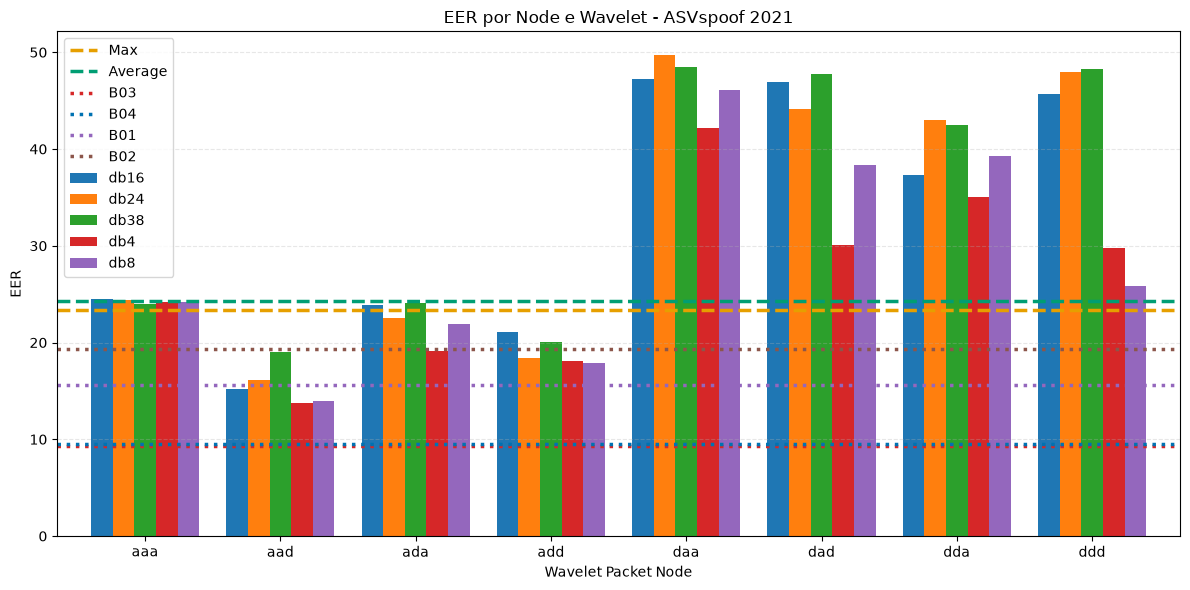

In [6]:

pivot = asv_2021.pivot_table(
    index="node",
    columns="wavelet",
    values="eer",
    aggfunc="mean"
)

eer_max = asv_2021.loc[
    asv_2021["pooling"] == "max", "eer"
].mean()

eer_avg = asv_2021.loc[
    asv_2021["pooling"] == "average", "eer"
].mean()

# Plot
ax = pivot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

# Pooling baselines
ax.axhline(
    y=eer_max,
    color="#E69F00",
    linestyle="--",
    linewidth=2.5,
    label="Max"
)

ax.axhline(
    y=eer_avg,
    color="#009E73",
    linestyle="--",
    linewidth=2.5,
    label="Average"
)

# ASVspoof 2021 baselines
ax.axhline(
    y=9.26,
    color="#D62728",
    linestyle=":",
    linewidth=2.5,
    label="B03"
)

ax.axhline(
    y=9.50,
    color="#0072B2",
    linestyle=":",
    linewidth=2.5,
    label="B04"
)

ax.axhline(
    y=15.62,
    color="#9467BD",
    linestyle=":",
    linewidth=2.5,
    label="B01"
)

ax.axhline(
    y=19.30,
    color="#8C564B",
    linestyle=":",
    linewidth=2.5,
    label="B02"
)

ax.set_xlabel("Wavelet Packet Node")
ax.set_ylabel("EER")
ax.set_title("EER por Node e Wavelet - ASVspoof 2021")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
